# Supplemental Figure 1, Panel A

Viability of GM12878 cells (from Trypan blue staining) at 24h after treatment with 0.01-100µM BRM014.

*Output: panel_a.pdf (full y-axis); panel_a_inset.pdf (restricted y-axis; inset)*

# Setup

In [1]:
#load packages
library(tidyverse)
library(Hmisc)
library(here)
here::i_am("figures/SuppFig1/PanelA/panel_a.ipynb")

theme_set(theme_bw() + theme(text=element_text(size=20), panel.grid=element_blank()))
          
sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘Hmisc’


The following objects are masked from ‘package:dplyr’:

    src, summarize


The following objects are masked from ‘package:base’:

    format.pval, units


here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig1/PanelA

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      Hmisc_5.2-3     lubridate_1.9.4 forcats_1.0.0  
 [5] stringr_1.5.1   dplyr_1.1.4     purrr_1.0.2     readr_2.1.5    
 [9] tidyr_1.3.1     tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pbdZMQ_0.3-13     xfun_0.49         ti

# Load data

In [5]:
data <- read.delim("BRM014_viability.txt", sep='\t')
data <- data %>% mutate(viability=100*(1 - Dead/Total))

# Generate plots

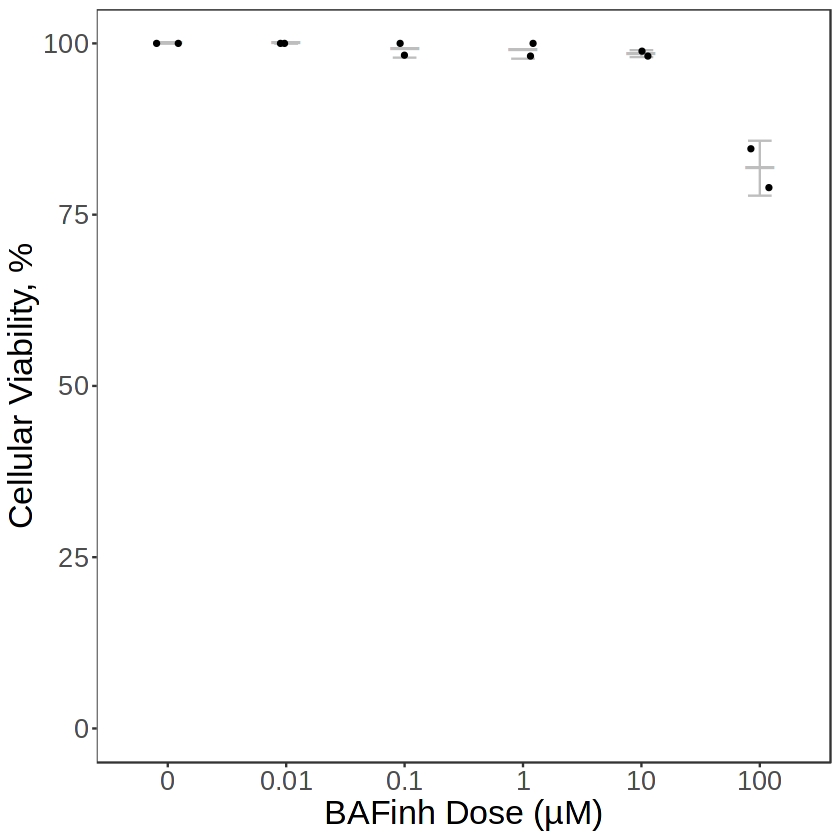

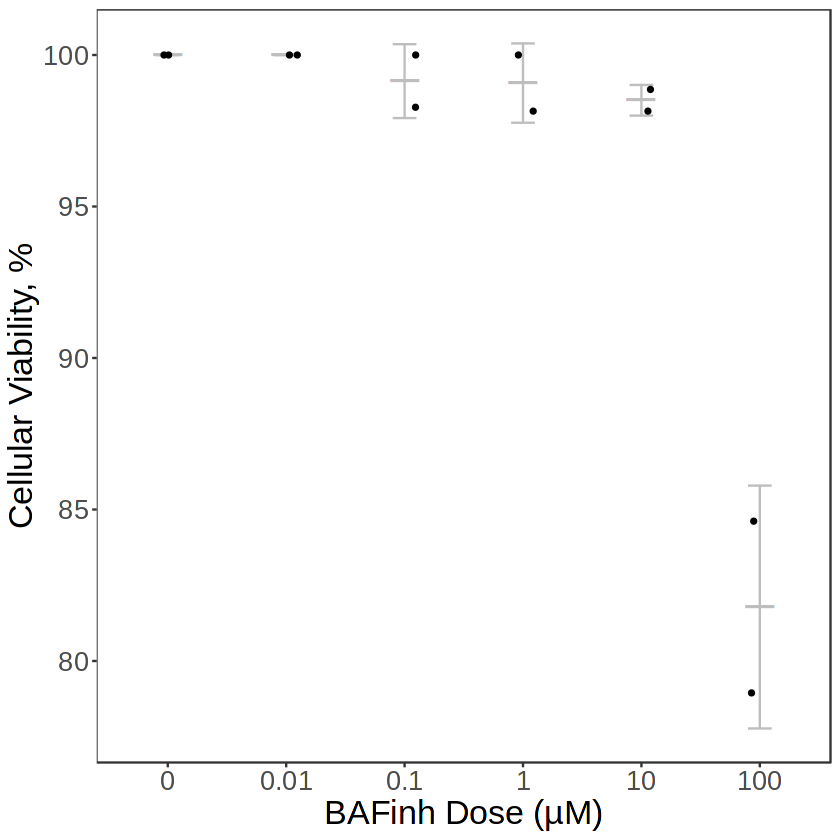

In [11]:
data %>% select(Dose_uM, Replicate, viability) %>% 
    ggplot(aes(x=factor(Dose_uM), y=viability)) + 
        # 
        stat_summary(fun.data=mean_sdl, geom="errorbar",fun.args=list(mult=1), width=.2, color="grey") + 
        stat_summary(fun=mean, geom="point", shape="_",color="grey", size=10) + 
        geom_point(shape=21,size=1,fill="black", position=position_jitter(height=0, width=.1)) + 
        ylim(0,100) + 
        xlab("BAFinh Dose (µM)") + ylab("Cellular Viability, %")
ggsave("panel_a.pdf", width=4, height=4)


data %>% select(Dose_uM, Replicate, viability) %>% 
    ggplot(aes(x=factor(Dose_uM), y=viability)) + 
        stat_summary(fun.data=mean_sdl, geom="errorbar",fun.args=list(mult=1), width=.2, color="grey") + 
        stat_summary(fun=mean, geom="point", shape="_",color="grey", size=10) + 
        geom_point(shape=21,size=1,fill="black", position=position_jitter(height=0, width=.1)) + 
        xlab("BAFinh Dose (µM)") + ylab("Cellular Viability, %")
ggsave("panel_a_inset.pdf", width=4, height=4)


# Statistics

In [7]:
#t.test(data[data$Dose_uM==0,]$viability, data[data$Dose_uM==0.01,]$viability)
t.test(data[data$Dose_uM==0,]$viability, data[data$Dose_uM==0.1,]$viability)
t.test(data[data$Dose_uM==0,]$viability, data[data$Dose_uM==1,]$viability)
t.test(data[data$Dose_uM==0,]$viability, data[data$Dose_uM==10,]$viability)
t.test(data[data$Dose_uM==0,]$viability, data[data$Dose_uM==100,]$viability)


	Welch Two Sample t-test

data:  data[data$Dose_uM == 0, ]$viability and data[data$Dose_uM == 0.1, ]$viability
t = 1, df = 1, p-value = 0.5
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 -10.09156  11.81569
sample estimates:
mean of x mean of y 
100.00000  99.13793 



	Welch Two Sample t-test

data:  data[data$Dose_uM == 0, ]$viability and data[data$Dose_uM == 1, ]$viability
t = 1, df = 1, p-value = 0.5
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 -10.83908  12.69093
sample estimates:
mean of x mean of y 
100.00000  99.07407 



	Welch Two Sample t-test

data:  data[data$Dose_uM == 0, ]$viability and data[data$Dose_uM == 10, ]$viability
t = 4.1765, df = 1, p-value = 0.1496
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 -3.051462  6.039678
sample estimates:
mean of x mean of y 
100.00000  98.50589 



	Welch Two Sample t-test

data:  data[data$Dose_uM == 0, ]$viability and data[data$Dose_uM == 100, ]$viability
t = 6.4286, df = 1, p-value = 0.09824
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 -17.79086  54.22811
sample estimates:
mean of x mean of y 
100.00000  81.78138 
